# Figuras e tabelas do artigo

Este notebook é a **única origem** das figuras e tabelas do artigo (seção 5 do CLAUDE.md). Ele lê
apenas `data/processed/` e grava em `reports/figures/` (PNG 300 dpi para o Word e PDF vetorial) e
em `reports/tables/` (CSV com vírgula decimal e XLSX). Ao final, escreve
`reports/figures/legendas.md` com título, nota e fonte de cada elemento, no formato ABNT (título
acima, fonte abaixo, fora da imagem).

Para regenerar tudo: `python -m patentes.dataset`, `python -m patentes.features` e, em seguida,
`jupyter nbconvert --to notebook --execute --inplace notebooks/2.0-apj-figuras-artigo.ipynb`.

In [1]:
from datetime import datetime
from pathlib import Path
import json
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PROJ_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJ_ROOT))

from patentes.config import (
    ANO_INICIO_ORIGEM_COMPLETA,
    CAMPOS_PT,
    CODIGO_LESTE_ASIATICO,
    ESCRITORIOS_DESTAQUE,
    FIGURES_DIR,
    MANIFEST_PATH,
    NOMES_PT,
    PAISES_DESTAQUE,
    PROCESSED_DATA_DIR,
    REGIOES_OMPI,
    TABLES_DIR,
)
from patentes.plots import (
    CORES_PAISES,
    FONTE_PADRAO,
    TRACOS_PAISES,
    aplicar_estilo_artigo,
    eixo_percentual,
    formatar_br,
    salvar_figura,
)

aplicar_estilo_artigo()
TABLES_DIR.mkdir(parents=True, exist_ok=True)
LARGURA_FIGURA = 16 / 2.54  # área útil da página A4 com margens de 3 cm e 2 cm, em polegadas

2026-10-06 23:42:23.065 | INFO     | patentes.config:<module>:17 - PROJ_ROOT path is: C:\Users\ailto\1.projetos\artigo-simpori-patentes


In [2]:
ler = dict(keep_default_na=False, na_values=[''])  # 'NA' (Namíbia) não pode virar ausente

df_participacao_escritorio = pd.read_csv(PROCESSED_DATA_DIR / 'participacao_escritorio.csv', **ler)
df_participacao_origem = pd.read_csv(PROCESSED_DATA_DIR / 'participacao_origem.csv', **ler)
df_participacao_pct = pd.read_csv(PROCESSED_DATA_DIR / 'participacao_pct.csv', **ler)
df_concentracao = pd.read_csv(PROCESSED_DATA_DIR / 'concentracao.csv', **ler)
df_vtr = pd.read_csv(PROCESSED_DATA_DIR / 'vtr_decada.csv', **ler)

manifesto = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
data_acesso = min(
    datetime.fromisoformat(registro['extraido_em']).astimezone() for registro in manifesto.values()
).strftime('%d/%m/%Y')  # horário local; o manifesto grava em UTC
fonte_com_acesso = f'{FONTE_PADRAO} (acesso em {data_acesso}).'

legendas = []  # (elemento, título, nota, fonte), gravadas em legendas.md no fim
print(fonte_com_acesso)

Fonte: elaboração própria com base em WIPO Statistics Database (acesso em 06/10/2026).


In [3]:
def plotar_participacao(ax, df, codigos, ano_inicial=None):
    for codigo in codigos:
        serie = df.loc[df['codigo'] == codigo].sort_values('ano')
        if ano_inicial:
            serie = serie.loc[serie['ano'] >= ano_inicial]
        ax.plot(
            serie['ano'], serie['participacao'],
            color=CORES_PAISES.get(codigo, '#555555'),
            linestyle=TRACOS_PAISES.get(codigo, '-'),
            linewidth=1.6,
            label=NOMES_PT.get(codigo, codigo),
        )
    ax.set_xlabel('')
    ax.set_ylabel('Participação no total (%)')
    eixo_percentual(ax)
    ax.set_ylim(bottom=0)

## Figura 1: participação por região de escritório, 1997–2024

As regiões da OMPI só têm dados a partir de 1997. África, América Latina e Caribe e Oceania
somam menos de 7% em todo o período e aparecem agregadas como "Demais regiões".

regiao,América do Norte,Demais regiões,Europa,Ásia
ano,,,,
1997,21.6,6.9,22.9,48.6
2007,26.5,5.7,18.1,49.7
2014,22.9,4.2,12.9,60.0
2024,17.1,3.0,9.7,70.1


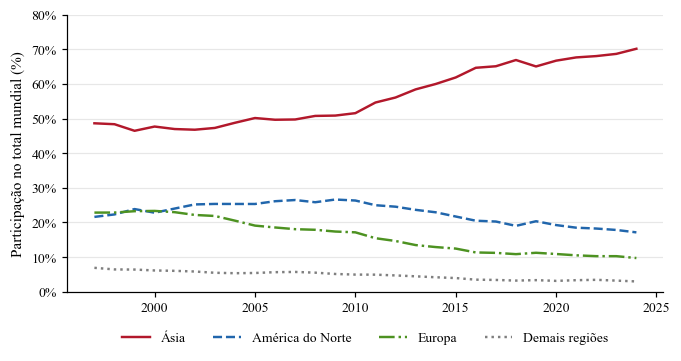

In [4]:
regioes_figura = {'R2': 'Ásia', 'R5': 'América do Norte', 'R3': 'Europa'}
estilo_regioes = {
    'Ásia': ('#b2182b', '-'),
    'América do Norte': ('#2166ac', '--'),
    'Europa': ('#4d9221', '-.'),
    'Demais regiões': ('#7f7f7f', ':'),
}

df_regioes = (
    df_participacao_escritorio
    .loc[df_participacao_escritorio['codigo'].isin(REGIOES_OMPI)]
    .assign(regiao=lambda d: d['codigo'].map(regioes_figura).fillna('Demais regiões'))
    .groupby(['ano', 'regiao'], as_index=False)['participacao']
    .sum()
)

fig, ax = plt.subplots(figsize=(LARGURA_FIGURA, 3.4))
for regiao, (cor, traco) in estilo_regioes.items():
    serie = df_regioes.loc[df_regioes['regiao'] == regiao]
    ax.plot(serie['ano'], serie['participacao'], color=cor, linestyle=traco, linewidth=1.6, label=regiao)
ax.set_ylabel('Participação no total mundial (%)')
eixo_percentual(ax)
ax.set_ylim(0, 80)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
salvar_figura(fig, 'figura1_regiao_escritorio')

legendas.append((
    'Figura 1',
    'Participação das regiões de escritório no total mundial de pedidos de patente (1997–2024)',
    'Pedidos diretos e entradas na fase nacional do PCT, por região do escritório que recebe o pedido. '
    '"Demais regiões": África, América Latina e Caribe e Oceania. A OMPI não publica a série regional antes de 1997.',
    fonte_com_acesso,
))
display(df_regioes.pivot(index='ano', columns='regiao', values='participacao').loc[[1997, 2007, 2014, 2024]].round(1))

## Figura 2: participação por país de origem, 1980–2024

A faixa cinza marca 1980–1993, quando cerca de um terço dos pedidos não tem origem identificada
(a OMPI ainda não cruzava escritório e origem). Nesse trecho, a participação dos países que
depositam no exterior fica subestimada.

codigo,CN,DE,JP,KR,US
ano,,,,,
1980,NaN,3.5,20.3,0.2,7.7
1994,1.2,7.2,41.0,3.6,18.4
2005,5.8,7.6,31.1,9.5,21.9
2014,31.2,5.6,17.3,8.6,18.8
2024,48.2,3.6,11.3,7.9,13.5


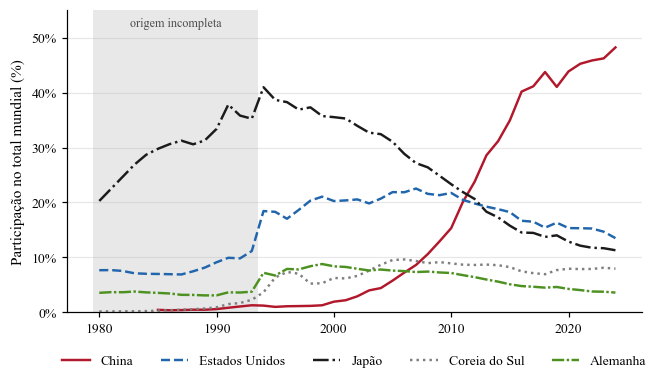

In [5]:
fig, ax = plt.subplots(figsize=(LARGURA_FIGURA, 3.6))
ax.axvspan(1979.5, ANO_INICIO_ORIGEM_COMPLETA - 0.5, color='#d9d9d9', alpha=0.6, linewidth=0)
ax.text(1986.5, 52, 'origem incompleta', ha='center', fontsize=8, color='#4d4d4d')
plotar_participacao(ax, df_participacao_origem, PAISES_DESTAQUE)
ax.set_ylim(0, 55)
ax.set_ylabel('Participação no total mundial (%)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
salvar_figura(fig, 'figura2_participacao_origem')

legendas.append((
    'Figura 2',
    'Participação de países selecionados no total mundial de pedidos de patente, por país de origem (1980–2024)',
    'O país de origem corresponde à residência do primeiro depositante. Até 1993 (área sombreada), cerca de um terço dos '
    'pedidos não tem origem identificada na base da OMPI, o que subestima os países que depositam no exterior.',
    fonte_com_acesso,
))
display(
    df_participacao_origem.loc[df_participacao_origem['codigo'].isin(PAISES_DESTAQUE)]
    .pivot(index='ano', columns='codigo', values='participacao')
    .loc[[1980, 1994, 2005, 2014, 2024]].round(1)
)

## Figura 3: participação no PCT por país de origem, 1995–2024

codigo,CN,DE,JP,KR,US,XEA
ano,,,,,,
1995,0.3,12.8,6.9,0.5,42.8,7.7
1998,0.5,14.0,9.1,0.8,41.7,10.4
2005,1.8,11.7,18.2,3.4,34.3,23.4
2019,22.3,7.3,19.9,7.2,21.6,49.3
2024,25.5,6.1,17.7,8.7,19.8,51.9


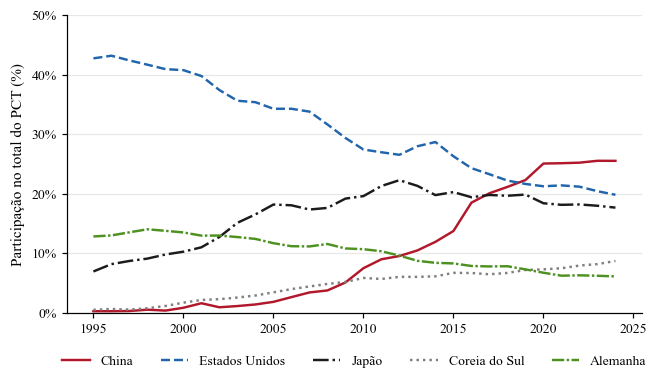

In [6]:
fig, ax = plt.subplots(figsize=(LARGURA_FIGURA, 3.6))
plotar_participacao(ax, df_participacao_pct, PAISES_DESTAQUE)
ax.set_ylim(0, 50)
ax.set_ylabel('Participação no total do PCT (%)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
salvar_figura(fig, 'figura3_participacao_pct')

legendas.append((
    'Figura 3',
    'Participação de países selecionados no total de pedidos internacionais via PCT, por país de origem (1995–2024)',
    'Pedidos PCT por data de depósito internacional, somados todos os escritórios receptores. '
    'A série da OMPI começa em 1995.',
    fonte_com_acesso,
))
display(
    df_participacao_pct.loc[df_participacao_pct['codigo'].isin(PAISES_DESTAQUE + [CODIGO_LESTE_ASIATICO])]
    .pivot(index='ano', columns='codigo', values='participacao')
    .loc[[1995, 1998, 2005, 2019, 2024]].round(1)
)

## Figura 4: participação dos principais escritórios, 1980–2024

Não consta da lista original da seção 5 do CLAUDE.md. Sustenta o resultado do resumo sobre a
liderança entre escritórios (Japão até 2005, Estados Unidos de 2006 a 2010, China desde 2011) e
cobre 1980–1996, período sem série regional.

,min,max
lider,,
CN,2011,2024
JP,1980,2005
US,2006,2010


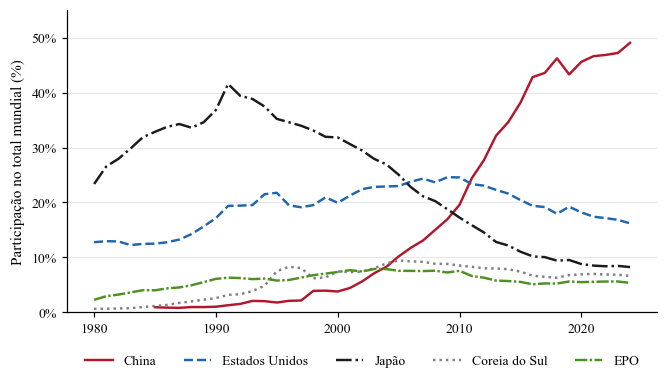

In [7]:
fig, ax = plt.subplots(figsize=(LARGURA_FIGURA, 3.6))
plotar_participacao(ax, df_participacao_escritorio, ESCRITORIOS_DESTAQUE)
ax.set_ylim(0, 55)
ax.set_ylabel('Participação no total mundial (%)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
salvar_figura(fig, 'figura4_participacao_escritorio')

legendas.append((
    'Figura 4',
    'Participação dos principais escritórios no total mundial de pedidos de patente (1980–2024)',
    'Pedidos recebidos por cada escritório, de residentes e não residentes. EPO: Escritório Europeu de Patentes. '
    'Para 1980–1984, o total mundial é a soma dos escritórios, pois a OMPI só publica o total a partir de 1985.',
    fonte_com_acesso,
))
display(
    df_concentracao.loc[df_concentracao['serie'] == 'escritorio']
    .groupby('lider')['ano'].agg(['min', 'max'])
)

## Tabela 1: CR5 e HHI por década

Médias decenais dos valores anuais. A década de 2020 cobre 2020–2024. Na série por origem, as
décadas de 1980 e 1990 incluem anos com origem incompleta e ficam marcadas.

In [8]:
periodos = {
    '1980–1989': (1980, 1989),
    '1990–1999': (1990, 1999),
    '2000–2009': (2000, 2009),
    '2010–2019': (2010, 2019),
    '2020–2024': (2020, 2024),
}
nomes_series = {'escritorio': 'Escritórios', 'origem': 'Países de origem', 'pct': 'PCT (origem)'}

linhas_tabela1 = []
for rotulo, (inicio, fim) in periodos.items():
    for serie, nome_serie in nomes_series.items():
        dados = df_concentracao.loc[(df_concentracao['serie'] == serie) & df_concentracao['ano'].between(inicio, fim)]
        if dados.empty:
            continue
        linhas_tabela1.append({
            'Período': rotulo,
            'Série': nome_serie,
            'Anos': f"{dados['ano'].min()}–{dados['ano'].max()}",
            'CR5 (%)': dados['cr5'].mean(),
            'HHI': dados['hhi'].mean(),
        })

tabela1 = (
    pd.DataFrame(linhas_tabela1)
    .pivot(index='Período', columns='Série', values=['CR5 (%)', 'HHI'])
    .reindex(columns=['Escritórios', 'Países de origem', 'PCT (origem)'], level=1)
)
tabela1_formatada = tabela1.apply(
    lambda coluna: coluna.map(lambda v: '' if pd.isna(v) else formatar_br(v, 1 if coluna.name[0] == 'CR5 (%)' else 0))
)
display(tabela1_formatada)

tabela1.round(1).to_csv(TABLES_DIR / 'tabela1_concentracao.csv', sep=';', decimal=',', encoding='utf-8-sig')
tabela1_formatada.to_excel(TABLES_DIR / 'tabela1_concentracao.xlsx')

legendas.append((
    'Tabela 1',
    'Razão de concentração dos cinco maiores (CR5) e índice Herfindahl-Hirschman (HHI) dos pedidos de patente, por década (1980–2024)',
    'Médias decenais de valores anuais; 2020–2024 tem cinco anos. Participações calculadas sobre o total mundial; '
    'HHI de 0 a 10.000. Na série por país de origem, os anos até 1993 têm cerca de um terço dos pedidos sem origem '
    'identificada. A série PCT começa em 1995.',
    fonte_com_acesso,
))

CR5 (%)                                       HHI  \
Série     Escritórios Países de origem PCT (origem) Escritórios   
Período                                                           
1980–1989        71,4             53,8                    1.548   
1990–1999        73,4             66,8         75,1       1.866   
2000–2009        74,1             74,1         71,9       1.473   
2010–2019        81,9             81,4         75,3       2.035   
2020–2024        85,1             84,5         78,4       2.676   

                                         
Série     Países de origem PCT (origem)  
Período                                  
1980–1989            1.054               
1990–1999            1.733        2.145  
2000–2009            1.612        1.745  
2010–2019            1.879        1.465  
2020–2024            2.561        1.532

## Tabela 2: VTR da China nos dez campos de maior peso, por década

Campos ordenados pelo peso no total mundial de publicações na década 2014–2023. Os nomes dos
campos são tradução do projeto (`CAMPOS_PT` em `patentes/config.py`).

In [9]:
ultima_decada = df_vtr['decada'].max()
top10_campos = (
    df_vtr.loc[df_vtr['decada'] == ultima_decada]
    .drop_duplicates('campo')
    .nlargest(10, 'participacao_campo_no_mundo')
    [['campo', 'participacao_campo_no_mundo']]
)

tabela2 = (
    df_vtr.loc[(df_vtr['codigo'] == 'CN') & df_vtr['campo'].isin(top10_campos['campo'])]
    .pivot(index='campo', columns='decada', values='vtr')
    .loc[top10_campos['campo']]
    .assign(peso_mundial=top10_campos.set_index('campo')['participacao_campo_no_mundo'])
)
tabela2.index = [f'{campo}. {CAMPOS_PT[campo]}' for campo in tabela2.index]
tabela2.index.name = 'Campo tecnológico'
tabela2 = tabela2.rename(columns={'peso_mundial': f'Peso no mundo, {ultima_decada} (%)'})

tabela2_formatada = tabela2.apply(
    lambda coluna: coluna.map(lambda v: '' if pd.isna(v) else formatar_br(v, 1 if coluna.name.startswith('Peso') else 2))
)
display(tabela2_formatada)

tabela2.round(2).to_csv(TABLES_DIR / 'tabela2_vtr_china.csv', sep=';', decimal=',', encoding='utf-8-sig')
tabela2_formatada.to_excel(TABLES_DIR / 'tabela2_vtr_china.xlsx')

legendas.append((
    'Tabela 2',
    'Índice de vantagem tecnológica revelada (VTR) da China nos dez campos tecnológicos de maior peso mundial, por década (1984–2023)',
    'VTR calculada sobre a soma das publicações de patentes de cada decênio, por país de origem; VTR > 1 indica '
    'especialização relativa. Campos da classificação da OMPI (35 campos), ordenados pelo peso no total mundial '
    f'de publicações em {ultima_decada}. A década 1984–1993 tem cobertura incompleta da origem.',
    fonte_com_acesso,
))

decada,1984–1993,1994–2003,2004–2013,2014–2023,"Peso no mundo, 2014–2023 (%)"
Campo tecnológico,,,,,
6. Tecnologia da computação,"0,50","0,97","0,83","1,18","9,5"
"1. Máquinas, aparelhos e energia elétrica","0,88","0,72","1,03","0,95","6,8"
10. Medição,"0,99","0,69","1,33","1,23","5,5"
4. Comunicação digital,"0,15","0,59","1,72","1,00","5,1"
13. Tecnologia médica,"1,49","0,87","0,45","0,64","4,9"
32. Transporte,"0,88","0,55","0,55","0,70","4,3"
29. Outras máquinas especiais,"1,07","0,92","1,19","1,16","3,7"
35. Engenharia civil,"1,11","0,88","1,17","1,16","3,7"
16. Produtos farmacêuticos,"0,81","2,87","1,30","0,75","3,4"


## Legendas

Grava `reports/figures/legendas.md`, para copiar título, nota e fonte de cada elemento para o texto.

In [10]:
texto_legendas = ['# Legendas das figuras e tabelas', '', f'Gerado por notebooks/2.0-apj-figuras-artigo.ipynb em {datetime.now():%d/%m/%Y}.', '']
for elemento, titulo, nota, fonte in legendas:
    texto_legendas += [f'## {elemento}', '', f'**{elemento}: {titulo}**', '', f'Nota: {nota}', '', fonte, '']
(FIGURES_DIR / 'legendas.md').write_text('\n'.join(texto_legendas), encoding='utf-8')

display(pd.DataFrame(
    sorted(p.name for p in [*FIGURES_DIR.glob('*.png'), *FIGURES_DIR.glob('*.pdf'), *TABLES_DIR.glob('tabela*')]),
    columns=['arquivo_gerado'],
))

,arquivo_gerado
0,figura1_regiao_escritorio.pdf
1,figura1_regiao_escritorio.png
2,figura2_participacao_origem.pdf
3,figura2_participacao_origem.png
4,figura3_participacao_pct.pdf
5,figura3_participacao_pct.png
6,figura4_participacao_escritorio.pdf
7,figura4_participacao_escritorio.png
8,tabela1_concentracao.csv
9,tabela1_concentracao.xlsx
